# Beat 10: Limitações

**Pergunta:** Quais são os limites?

Este notebook aborda as limitações práticas do Grad-CAM, como a resolução grosseira dos mapas (grade $14\times 14$), a necessidade de interpolação bicúbica para o tamanho original da imagem ($224\times 224$) e menção a alternativas modernas como Grad-CAM++ e Score-CAM.

In [1]:
import os
import sys

sys.path.append(os.path.abspath('.'))
sys.path.append(os.path.abspath('notebooks'))

import torch
import matplotlib.pyplot as plt
from PIL import Image

import deck
from gradcam import gradcam
from gradcam.models import load_model, preprocess, imagenet_labels
from gradcam.viz import figure_grid, overlay, tensor_to_numpy
from gradcam.models import denormalize

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = load_model("vgg16", device=device)
labels = imagenet_labels()
print(f"VGG-16 carregado em {device}")

VGG-16 carregado em cpu


## Resolução Grosseira do Grad-CAM ($14\times 14$ vs $224\times 224$)

Visualizando o mapa antes do upsample bilinear/bicúbico e o resultado final suavizado.

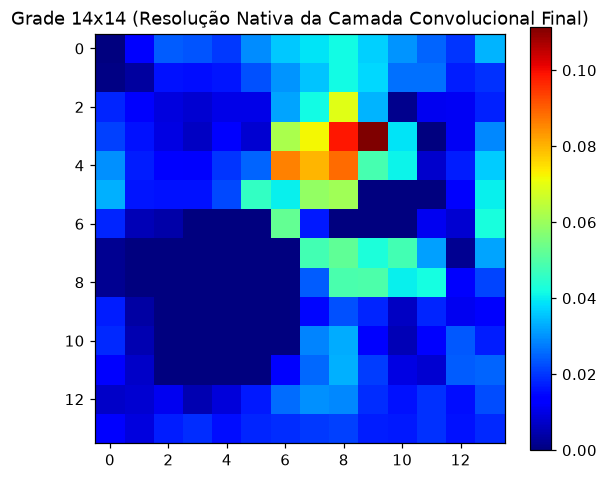

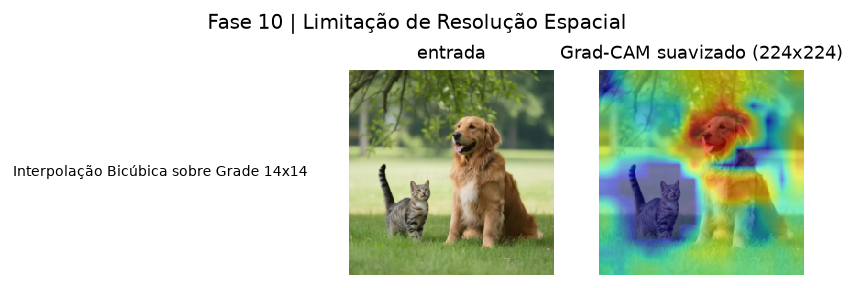

Resolução nativa do mapa: (14, 14) -> Interpolado para 224x224


In [2]:
base = "notebooks/assets" if os.path.isdir("notebooks/assets") else "assets"
image = Image.open(os.path.join(base, "cat_dog.jpg")).convert("RGB")
x = preprocess(image)
image_rgb = tensor_to_numpy(denormalize(x))

class_idx = int(model(x).argmax(dim=1).item())

# Extrai mapa bruto na camada final (14x14) e upsample
gc_map, _ = gradcam(model, x, class_idx=class_idx)
gc_map = gc_map.detach()

DISPLAY_HIGH, DISPLAY_GAMMA = 0.99, 0.5

fig, ax = plt.subplots(figsize=(6, 5), dpi=110)
im = ax.imshow(gc_map.cpu().numpy(), cmap="jet", interpolation="nearest")
ax.set_title("Grade 14x14 (Resolução Nativa da Camada Convolucional Final)")
plt.colorbar(im, ax=ax)
plt.show()

fig = figure_grid(
    [
        [
            image_rgb,
            overlay(image_rgb, gc_map, high=DISPLAY_HIGH, gamma=DISPLAY_GAMMA),
        ]
    ],
    col_titles=("entrada", "Grad-CAM suavizado (224x224)"),
    row_titles=["Interpolação Bicúbica sobre Grade 14x14"],
    suptitle="Fase 10 | Limitação de Resolução Espacial",
)
plt.show()

print(f"Resolução nativa do mapa: {tuple(gc_map.shape)} -> Interpolado para 224x224")